# Browsing Behaviour — Cleaning, Validation and Connections

**IT2226 · ShopSphere · Person A**

| My tables | Rows | Role |
|---|---|---|
| `sessions.csv` | 1,442,550 | Every website/app visit by our 80,000 customers. The largest table in the pack and the raw material for the sequence model |
| `geo_data.csv` | 100 | Socio-economic attributes per region. A lookup table |
| `campaign_daily_performance.csv` | 11,867 | Marketing platform's daily report per campaign |

### How my tables connect to the rest of the pack

```
                         geo_data  (geo_ip_region)
                            ▲              ▲
          geo_ip_region     │              │  region
                            │              │
 marketing_campaigns ◀── sessions ──▶ customers ──▶ train / test (target)
   (campaign_id)            │   customer_id
          ▲                 │
          │                 │  same customer, same day
 campaign_daily_performance  ▼
   (campaign_id, date)    transactions
```

Every arrow is a join key. Part of this notebook's job is to **test** each arrow rather than assume it: does the key resolve, and does the data on either side agree?

### How to read this notebook

Each step has three parts — **what** I'm doing, **why**, and **what I found**. Decisions marked 🔸 are choices, not facts: I should be able to defend each one, and the team should agree them before they go into the shared `src/clean/browsing.py`.

The notebook does **cleaning** (fixing representation) and **EDA** (understanding). It does not do feature engineering or fit anything — imputation values and scalers are learned from training rows only, inside the model pipeline. Doing that here would leak validation data into training.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ---- CONFIGURE ------------------------------------------------------------
DATA_DIR = Path('data')
OUT_DIR  = Path('browsing_dataset')   # Person A's cleaned output
# ---------------------------------------------------------------------------

CUTOFF = pd.Timestamp('2024-09-30')
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)

# One hue. INK = the series; GREY = the comparison group; RAMP = ordered bands
# (light = low, dark = high); FLAG = anomalies and reference lines only.
INK, GREY, FLAG = '#3e6fb0', '#a9b1bd', '#c4622d'
RAMP = ['#cfe0f3', '#9dc0e3', '#5f91c8', '#2e5e96']

plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b9bec6', 'axes.labelcolor': '#3d4450',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': '#e6e9ee', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': '#5b626e', 'ytick.color': '#5b626e', 'font.size': 9.5,
    'legend.frameon': False,
})

def pct(ax, axis='y'):
    f = mticker.PercentFormatter(1.0)
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(f)

def label_bars(ax, bars, fmt='{:.1%}', size=8.5):
    for b in bars:
        h = b.get_height()
        if np.isfinite(h):
            ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h),
                        ha='center', va='bottom', fontsize=size, color='#3d4450',
                        xytext=(0, 2), textcoords='offset points')

QUALITY = []
def note(table, issue, rows, action):
    QUALITY.append({'table': table, 'issue': issue, 'rows': int(rows), 'action': action})
    print(f'  [{table}] {issue}: {int(rows):,}  ->  {action}')

## 1. Load

My three tables, plus the tables they join to. I load the neighbours only to test the connections — I don't clean them; they belong to Persons B, C and D.

In [2]:
se_raw  = pd.read_csv(DATA_DIR / 'sessions.csv')
geo_raw = pd.read_csv(DATA_DIR / 'geo_data.csv')
cdp_raw = pd.read_csv(DATA_DIR / 'campaign_daily_performance.csv')

# neighbours -- read-only, for testing joins
customers = pd.read_csv(DATA_DIR / 'customers.csv', usecols=['customer_id', 'region'])
campaigns = pd.read_csv(DATA_DIR / 'marketing_campaigns.csv')
train     = pd.read_csv(DATA_DIR / 'train.csv')
tx        = (pd.read_csv(DATA_DIR / 'transactions.csv',
                         usecols=['transaction_id', 'customer_id', 'transaction_timestamp'])
             .drop_duplicates('transaction_id'))   # Person C's dedup, applied so my joins are honest

for name, df in [('sessions', se_raw), ('geo_data', geo_raw), ('campaign_daily', cdp_raw)]:
    print(f'{name:<16} {df.shape[0]:>10,} rows  {df.shape[1]:>3} cols')
print()
se_raw.head()

sessions          1,442,550 rows   11 cols
geo_data                100 rows    5 cols
campaign_daily       11,867 rows    8 cols



,session_id,customer_id,session_timestamp,session_duration,pages_viewed,cart_additions,bounce_flag,traffic_source,device_type,campaign_id,geo_ip_region
0,0,30972,2022-01-01,535.1,4.0,2,No,Organic,Mobile,NaN,region_2
1,1,14277,2022-01-01,516.5,4.0,2,No,Direct,Mobile,NaN,region_85
2,2,48058,2022-01-01,254.6,6.0,1,0,Organic,Desktop,NaN,region_66
3,3,78555,2022-01-01,548.3,14.0,1,No,Social,Mobile,NaN,region_40
4,4,61482,2022-01-01,505.7,7.0,1,0,Organic,Desktop,NaN,region_11


**What to notice.** `session_timestamp` is a date, not a time — so "same day" is the finest resolution anything in this table supports. `campaign_id` is a float, because pandas can't hold blanks in an integer column. Both shape later decisions.

---

## 2. Clean `sessions.csv`

### 2.1 Dates and the cutoff

**Why first:** every later step that compares dates depends on this being a real datetime, and the cutoff is the single most important rule in the project. If anything in this table is dated after 30 Sep 2024, it's information the model must not see.

In [3]:
se = se_raw.copy()
se['session_date'] = pd.to_datetime(se.session_timestamp)
se = se.drop(columns='session_timestamp')

print('range:', se.session_date.min().date(), '->', se.session_date.max().date())
after = (se.session_date > CUTOFF).sum()
print('sessions after cutoff:', after)
assert after == 0, 'sessions dated after the cutoff -- leakage'

range: 2022-01-01 -> 2024-09-30
sessions after cutoff: 0


**Found.** The range ends exactly on the cutoff, nothing after. This table is safe on dates — which is worth stating, because the deliveries table is *not* (510 `delivered_date` values fall after the cutoff — Person D's table).

### 2.2 `bounce_flag` — six encodings of two values

**Why it matters:** a model given `"Yes"`, `"TRUE"` and `"1"` as three separate categories learns three different things about one fact.

In [4]:
print(se.bounce_flag.astype(str).value_counts().to_string())

bounce_flag
0        478798
No       478363
FALSE    477991
TRUE       2499
Yes        2458
1          2441


**Found.** The six spellings split evenly: ~478k each of `0`/`No`/`FALSE` and ~2.5k each of `1`/`TRUE`/`Yes`. An even split across spellings means the encoding was assigned at random per row — an injected fault, not two systems with different conventions merging.

In [5]:
TRUE_SET  = {'Yes', 'TRUE', '1', 'Y', 'True', 'true', 'yes'}
FALSE_SET = {'No', 'FALSE', '0', 'N', 'False', 'false', 'no'}

def to_bool(s, name):
    """Map every known spelling; FAIL LOUDLY on anything unexpected rather than
    silently turning it into False. (Replace with the team's shared helper.)"""
    v = s.astype(str).str.strip()
    unknown = set(v.unique()) - TRUE_SET - FALSE_SET
    if unknown:
        raise ValueError(f'{name}: unmapped values {unknown}')
    return v.isin(TRUE_SET)

note('sessions', 'bounce_flag in 6 encodings', len(se), 'mapped to bool')
se['bounce_flag'] = to_bool(se.bounce_flag, 'bounce_flag')
print(f'bounce rate: {se.bounce_flag.mean():.2%}')

  [sessions] bounce_flag in 6 encodings: 1,442,550  ->  mapped to bool


bounce rate: 0.51%


**Found — and this one is worth questioning.** A bounce rate of about 0.5% is implausible for a real e-commerce site, where 30–60% is normal. Either the generator defined "bounce" differently or it's unrealistic.

🔸 **Decision:** keep the column, but treat `bounce_flag` as a weak feature and say so in the report. Writing "this value isn't plausible for a real site" is a stronger answer in an interrogation than silently using it.

### 2.3 `traffic_source` and `device_type` — case variants

In [6]:
for col in ['traffic_source', 'device_type']:
    raw = sorted(se[col].astype(str).unique())
    se[col] = se[col].astype(str).str.strip().str.lower()
    clean = sorted(se[col].unique())
    note('sessions', f'{col} case variants', len(raw) - len(clean),
         f'{len(raw)} spellings -> {len(clean)}: {clean}')

  [sessions] traffic_source case variants: 10  ->  15 spellings -> 5: ['ads', 'direct', 'email', 'organic', 'social']


  [sessions] device_type case variants: 6  ->  9 spellings -> 3: ['desktop', 'mobile', 'tablet']


**Why lowercase is safe here but not for countries:** every variant differs only in case — `ADS`, `Ads`, `ads`. Nothing collapses wrongly. Compare `customers.country_code`, where `GB` and `UK` are different strings meaning the same thing and need a human decision. Lowercasing is only correct when case is the *only* difference — I checked the raw lists above before applying it.

### 2.4 `pages_viewed` — 72k missing, and a rule hidden in the data

**Why not just fill with the median:** first test whether the missingness has a structure. If it does, the structure tells you how to fill.

In [7]:
print('missing pages_viewed:', se.pages_viewed.isna().sum())
print()
print('pages_viewed among BOUNCED sessions:')
print(se.loc[se.bounce_flag, 'pages_viewed'].value_counts(dropna=False).to_string())
print()
print(f'missing rate | bounced:     {se.loc[se.bounce_flag, "pages_viewed"].isna().mean():.2%}')
print(f'missing rate | not bounced: {se.loc[~se.bounce_flag, "pages_viewed"].isna().mean():.2%}')

missing pages_viewed: 71958

pages_viewed among BOUNCED sessions:
pages_viewed
1.0    7049
NaN     349

missing rate | bounced:     4.72%
missing rate | not bounced: 4.99%


**Found two things.**

1. **Every bounced session that has a value shows exactly 1 page.** That's the definition of a bounce. So for the 349 bounced sessions with a null, the answer is known: **1**. That's not imputation, it's deduction — deterministic, safe to apply here.
2. **The missing rate is the same whether or not the session bounced** (~5%). So the remaining ~71,600 nulls are *not* explained by bounces. They're genuinely unknown and need a learned imputation — which belongs in the pipeline, fitted on training rows only.

🔸 **Decision:** deduce the 349; flag all 71,958; leave the rest null for the pipeline.

In [8]:
se['pages_viewed_missing'] = se.pages_viewed.isna()
deducible = se.bounce_flag & se.pages_viewed.isna()
se.loc[deducible, 'pages_viewed'] = 1
note('sessions', 'pages_viewed null on bounced sessions', deducible.sum(), 'set to 1 (a bounce is 1 page by definition)')
note('sessions', 'pages_viewed null otherwise', se.pages_viewed.isna().sum(), 'flagged; imputation deferred to pipeline')

  [sessions] pages_viewed null on bounced sessions: 349  ->  set to 1 (a bounce is 1 page by definition)
  [sessions] pages_viewed null otherwise: 71,609  ->  flagged; imputation deferred to pipeline


### 2.5 More cart additions than pages viewed: impossible, or just rare?

**Why look for this:** encoding problems are obvious. Contradictions between columns are not, and finding them shows you understood what the columns mean. But a contradiction is only a fault if the rule behind it is real. "One page, at most one item" is not: a listing page, a recommendation strip or a quantity of two can all add several items from a single page. So test the pattern before deciding.

In [9]:
known = se.pages_viewed.notna()
more = known & (se.cart_additions > se.pages_viewed)
print('cart_additions > pages_viewed:', more.sum(), f'({more.mean():.3%} of sessions)')
print('by how many items:', (se.cart_additions - se.pages_viewed)[more].astype(int).value_counts().sort_index().to_dict())
print('pages viewed in those sessions:', se.pages_viewed[more].astype(int).value_counts().sort_index().to_dict())
print(f'cart additions per page overall: {se.cart_additions[known].sum() / se.pages_viewed[known].sum():.3f}')
print('most cart additions in any session:', se.cart_additions.max())
se.loc[more, ['session_id', 'pages_viewed', 'cart_additions', 'session_duration']].head(6)

cart_additions > pages_viewed: 144 (0.010% of sessions)
by how many items: {1: 134, 2: 10}
pages viewed in those sessions: {1: 16, 2: 50, 3: 49, 4: 19, 5: 7, 6: 3}
cart additions per page overall: 0.128
most cart additions in any session: 12


,session_id,pages_viewed,cart_additions,session_duration
4254,4254,2.0,3,145.2
9235,9235,2.0,3,181.4
74040,74040,5.0,6,374.6
74421,74421,2.0,3,317.7
115390,115390,3.0,4,129.7
136492,136492,3.0,4,137.9


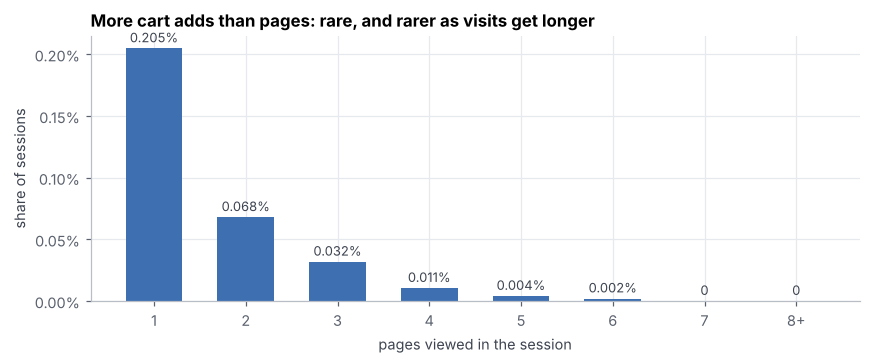

,sessions,more cart adds than pages,share
1,"7,814",16,0.205%
2,"73,577",50,0.068%
3,"153,914",49,0.032%
4,"180,839",19,0.011%
5,"171,617",7,0.004%
6,"148,246",3,0.002%
7,"123,116",0,0.000%
8+,"511,818",0,0.000%


In [10]:
# Is it a fault (a cluster, a gap, a fixed offset) or the edge of a normal count?
pv = se.loc[known, 'pages_viewed'].clip(upper=8).astype(int)
over = (se.cart_additions > se.pages_viewed)[known]
g = pd.DataFrame({'sessions': over.groupby(pv).size(), 'more cart adds than pages': over.groupby(pv).sum(),
                  'share': over.groupby(pv).mean()})
g.index = [str(i) if i < 8 else '8+' for i in g.index]

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(g.index, g.share, color=INK, width=0.62)
for b, v in zip(bars, g.share):
    ax.annotate(f'{v:.3%}' if v else '0', (b.get_x() + b.get_width() / 2, v), ha='center', va='bottom',
                fontsize=8.5, color='#3d4450', xytext=(0, 2), textcoords='offset points')
ax.set_title('More cart adds than pages: rare, and rarer as visits get longer')
ax.set_xlabel('pages viewed in the session'); ax.set_ylabel('share of sessions')
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.0005))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=2))
plt.tight_layout(); plt.show()
g.style.format({'sessions': '{:,}', 'more cart adds than pages': '{:,}', 'share': '{:.3%}'})

**Found: a tail, not a fault.** 144 sessions (0.01%) add more items than they viewed pages. In 134 of them the excess is one item, in the other 10 two. They sit on short visits (mostly 1–3 pages), and the share falls steadily as visits get longer: 0.20% at one page, 0.07% at two, under 0.01% from five. That is what a random count of items looks like near its limit when there are few pages. There is no separate cluster or empty gap, unlike session duration in 2.6, and the largest basket in any session is 12 items.

🔸 **Decision (revised 19 Nov):** keep the values as they are, with no cap and no flag. My first version capped them at `pages_viewed` as "logically impossible"; this test shows the rule I assumed (one item per page) doesn't hold. Capping would change real values to fit a rule the data doesn't follow.

In [11]:
note('sessions', 'cart_additions > pages_viewed', more.sum(),
     'kept: tail of the count, several items can be added from one page (revised; was capped)')

  [sessions] cart_additions > pages_viewed: 144  ->  kept: tail of the count, several items can be added from one page (revised; was capped)


### 2.6 `session_duration` — a corrupted cluster, not just a long tail

**The tempting rule** is "anything over 24 hours is impossible, delete it." That's weak: a session *can* run that long if a tab is left open on a site that never times out. So instead of picking a round number, test whether the long sessions behave like real sessions.

`session_duration` is per **session** — one row per `session_id`, measured in seconds — not a daily total.

count    1,442,550
mean           430
std          1,897
min              8
50%            282
90%            730
99%          1,676
99.9%       22,146
max         89,948

largest empty gap above 1h: 2.8h -> 5.6h  (no sessions in between)


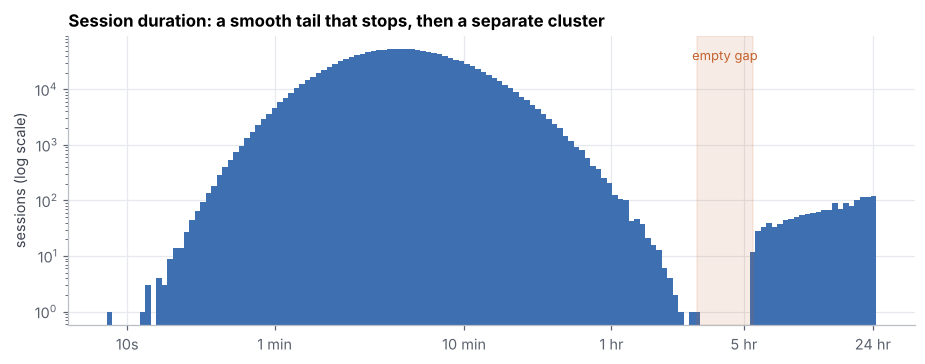

In [12]:
sd = se.session_duration
print(sd.describe(percentiles=[.5, .9, .99, .999]).apply(lambda v: f'{v:,.0f}').to_string())

# Where is the biggest empty stretch above one hour?
s = np.sort(sd[sd > 3_600].values)
i = np.diff(s).argmax()
print(f'\nlargest empty gap above 1h: {s[i]/3600:.1f}h -> {s[i+1]/3600:.1f}h  (no sessions in between)')

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(np.log10(sd), bins=140, color=INK)
ax.axvspan(np.log10(s[i]), np.log10(s[i+1]), color=FLAG, alpha=0.12)
ax.annotate('empty gap', ((np.log10(s[i]) + np.log10(s[i+1])) / 2, ax.get_ylim()[1] * 0.6),
            ha='center', color=FLAG, fontsize=8.5)
ticks = [10, 60, 600, 3_600, 18_000, 86_400]
ax.set_xticks(np.log10(ticks), ['10s', '1 min', '10 min', '1 hr', '5 hr', '24 hr'])
ax.set_yscale('log')
ax.set_title('Session duration: a smooth tail that stops, then a separate cluster')
ax.set_ylabel('sessions (log scale)')
plt.tight_layout(); plt.show()

**Test 1 — the shape.** On a log-scaled count axis a natural long tail tapers away smoothly. This one stops dead around 2.8 hours, nothing exists until about 5.6 hours, then a separate cluster runs out to 25 hours. Real behaviour doesn't stop and restart; values appended from somewhere else do.

In [13]:
bands = {'normal (under 1h)': sd <= 3_600,
         'natural tail (1h to the gap)': (sd > 3_600) & (sd <= 18_000),
         'cluster (over 5h)': sd > 18_000}
rows = []
for name, m in bands.items():
    g = se[m]
    rows.append({'band': name, 'sessions': len(g),
                 'median duration (s)': g.session_duration.median(),
                 'median pages': g.pages_viewed.median(),
                 'median cart adds': g.cart_additions.median(),
                 'median secs per page': (g.session_duration / g.pages_viewed).median(),
                 'corr(duration, pages)': g[['session_duration', 'pages_viewed']].corr().iloc[0, 1]})
pd.DataFrame(rows).set_index('band').style.format({
    'sessions': '{:,}', 'median duration (s)': '{:,.0f}', 'median pages': '{:.0f}',
    'median cart adds': '{:.0f}', 'median secs per page': '{:,.0f}', 'corr(duration, pages)': '{:+.2f}'})

,sessions,median duration (s),median pages,median cart adds,median secs per page,"corr(duration, pages)"
band,,,,,,
normal (under 1h),"1,440,506",281,6,1,46,+0.63
natural tail (1h to the gap),560,"4,195",28,2,158,+0.18
cluster (over 5h),"1,484","54,945",6,1,"8,360",-0.01


**Test 2 — the activity.** Sessions in the cluster view the *same* number of pages and add the *same* number of items as a normal five-minute visit, but over many hours: thousands of seconds per page instead of tens. A genuinely long visit would show more browsing, not the same browsing stretched thin.

**Test 3 — the relationship.** In normal sessions, duration and pages viewed move together, as they should. In the cluster, the correlation is roughly zero. The duration value has come loose from everything else in the row.

**Test 4 — can it be repaired?** If these were minutes accidentally stored as seconds, dividing by 60 would recreate the normal shape.

In [14]:
clus = se.loc[sd > 18_000, 'session_duration']
print('normal body quantiles (10/50/90):', se.loc[sd <= 3_600, 'session_duration'].quantile([.1, .5, .9]).round().tolist())
print('cluster / 60 quantiles (10/50/90):', (clus / 60).quantile([.1, .5, .9]).round().tolist())

normal body quantiles (10/50/90): [115.0, 281.0, 726.0]
cluster / 60 quantiles (10/50/90): [455.0, 916.0, 1383.0]


It doesn't match, so this isn't a unit error and the true values can't be recovered.

🔸 **Decision:** null `session_duration` and flag the row for every session **over 5 hours (18,000s)**. Keep everything below.

**Why 5 hours, and why this isn't a "learned" threshold:** 5 hours sits inside the empty gap, where no session exists. Any threshold between about 2.8h and 5.6h removes exactly the same rows, so the choice isn't tuned to the data — it's a fixed rule justified by four pieces of evidence. That's different from a percentile cap, which moves whenever the data changes and therefore has to be fitted after the train/validation split.

The 1h-to-gap sessions stay. They sit on the smooth part of the curve and behave like real sessions; how much weight they get (log-transform, winsorise) is a modelling decision for the pipeline.

In [15]:
DURATION_CORRUPT_S = 18_000   # 5 hours: inside the empty 2.8h-5.6h gap; see evidence above
corrupt = se.session_duration > DURATION_CORRUPT_S
se['duration_corrupt'] = corrupt
se.loc[corrupt, 'session_duration'] = np.nan
note('sessions', 'session_duration in corrupted cluster (>5h)', corrupt.sum(),
     'nulled, flagged: normal activity over hours, uncorrelated with pages, separated by a gap')
note('sessions', 'session_duration 1h-5h (natural tail)', ((sd > 3_600) & (sd <= DURATION_CORRUPT_S)).sum(),
     'kept; transform in pipeline')

  [sessions] session_duration in corrupted cluster (>5h): 1,484  ->  nulled, flagged: normal activity over hours, uncorrelated with pages, separated by a gap
  [sessions] session_duration 1h-5h (natural tail): 560  ->  kept; transform in pipeline


### 2.7 `campaign_id` — blank means something

**Why not fill:** `DATA_README` says a blank `campaign_id` means the session didn't come from a campaign. Filling it would invent campaign traffic. Instead, make the meaning explicit.

In [16]:
se['from_campaign'] = se.campaign_id.notna()
se['campaign_id'] = se.campaign_id.astype('Int64')   # nullable integer: blanks stay blank
print(f'sessions from a campaign: {se.from_campaign.sum():,} ({se.from_campaign.mean():.1%})')
note('sessions', 'campaign_id blank', (~se.from_campaign).sum(), 'documented meaning: not from a campaign. Flag, not fill')

sessions from a campaign: 100,401 (7.0%)
  [sessions] campaign_id blank: 1,342,149  ->  documented meaning: not from a campaign. Flag, not fill


### 2.8 Integrity of every key in `sessions`

In [17]:
cust_ids = set(customers.customer_id)
camp_ids = set(campaigns.campaign_id)
geo_ids  = set(geo_raw.geo_ip_region)

checks = {
    'duplicate session_id':                      se.session_id.duplicated().sum(),
    'fully duplicate rows':                      se_raw.duplicated().sum(),
    'customer_id not in customers':              (~se.customer_id.isin(cust_ids)).sum(),
    'campaign_id not in marketing_campaigns':    (~se.campaign_id.dropna().isin(camp_ids)).sum(),
    'geo_ip_region not in geo_data':             (~se.geo_ip_region.isin(geo_ids)).sum(),
    'pages_viewed <= 0':                         (se.pages_viewed <= 0).sum(),
    'session_duration <= 0':                     (se.session_duration <= 0).sum(),
    'cart_additions < 0':                        (se.cart_additions < 0).sum(),
}
pd.Series(checks, name='violations').to_frame()

,violations
duplicate session_id,0
fully duplicate rows,0
customer_id not in customers,0
campaign_id not in marketing_campaigns,0
geo_ip_region not in geo_data,0
pages_viewed <= 0,0
session_duration <= 0,0
cart_additions < 0,0


**Found.** Every key resolves and there are no duplicates. Like the rest of the pack, the mess here is in *values*, not *relationships* — every arrow in the diagram at the top holds.

---

## 3. Validate `geo_data.csv`

A lookup table can't be "cleaned" much, but it can be **verified**. "No cleaning needed" with nothing behind it is a weak claim; the same statement with the checks shown is a finding.

In [18]:
geo = geo_raw.copy()
used_s = set(se.geo_ip_region); used_c = set(customers.region)

checks = {
    'duplicate regions':                          geo.geo_ip_region.duplicated().sum(),
    'sessions regions missing from geo_data':     len(used_s - geo_ids),
    'customer regions missing from geo_data':     len(used_c - geo_ids),
    'geo_data regions never seen in sessions':    len(geo_ids - used_s),
    'geo_data regions never seen in customers':   len(geo_ids - used_c),
    'nulls':                                      geo.isna().sum().sum(),
    'urban_ratio outside 0-1':                    ((geo.urban_ratio < 0) | (geo.urban_ratio > 1)).sum(),
    'internet_penetration outside 0-1':           ((geo.internet_penetration < 0) | (geo.internet_penetration > 1)).sum(),
    'average_income <= 0':                        (geo.average_income <= 0).sum(),
}
display(pd.Series(checks, name='violations').to_frame())
display(geo.describe().T[['min', '50%', 'max']].style.format('{:,.3f}'))
print(geo.region_tier.value_counts().to_dict())

,violations
duplicate regions,0
sessions regions missing from geo_data,0
customer regions missing from geo_data,0
geo_data regions never seen in sessions,0
geo_data regions never seen in customers,0
nulls,0
urban_ratio outside 0-1,0
internet_penetration outside 0-1,0
average_income <= 0,0


,min,50%,max
average_income,"10,703.823","48,095.656","77,784.173"
urban_ratio,0.303,0.630,0.941
internet_penetration,0.508,0.768,0.985


{'Tier1': 41, 'Tier2': 33, 'Tier3': 26}


**Found: clean on every test.** 100 regions, each used by both sessions and customers, no gaps in either direction, every rate in range.

One detail to note: `region_tier` is a string `'Tier1'..'Tier3'`. If it's ordinal (Tier 1 better than Tier 3) it should become 1–3; if it's just a label, one-hot. The data dictionary doesn't say which — a question for the report, not something to guess.

`region_74` has an average income around $10.7k, well below the rest. Plausible, so kept — but it's the kind of value worth one line.

---

## 4. Validate `campaign_daily_performance.csv`

In [19]:
cdp = cdp_raw.copy()
cdp['date'] = pd.to_datetime(cdp.date)
camps = campaigns.copy()
camps['start_date'] = pd.to_datetime(camps.start_date)
camps['end_date']   = pd.to_datetime(camps.end_date)
camps['campaign_budget'] = pd.to_numeric(camps.campaign_budget.astype(str).str.replace(r'[$,]', '', regex=True))

j = cdp.merge(camps[['campaign_id', 'start_date', 'end_date', 'campaign_budget', 'status']], on='campaign_id')

checks = {
    'duplicate (campaign_id, date)':              cdp.duplicated(['campaign_id', 'date']).sum(),
    'campaign_id not in marketing_campaigns':     (~cdp.campaign_id.isin(camp_ids)).sum(),
    'dates after cutoff':                         (cdp.date > CUTOFF).sum(),
    'rows outside the campaign\'s own window':    ((j.date < j.start_date) | (j.date > j.end_date)).sum(),
    'clicks > impressions':                       (cdp.clicks > cdp.impressions).sum(),
    'attributed_sessions > clicks':               (cdp.attributed_sessions > cdp.clicks).sum(),
    'attributed_orders > attributed_sessions':    (cdp.attributed_orders > cdp.attributed_sessions).sum(),
    'negative values':                            (cdp.select_dtypes('number') < 0).sum().sum(),
}
pd.Series(checks, name='violations').to_frame()

,violations
"duplicate (campaign_id, date)",0
campaign_id not in marketing_campaigns,0
dates after cutoff,0
rows outside the campaign's own window,0
clicks > impressions,0
attributed_sessions > clicks,0
attributed_orders > attributed_sessions,0
negative values,0


**Found: structurally clean.** Including the funnel order — impressions ≥ clicks ≥ sessions ≥ orders on every row. That's worth testing explicitly: a funnel that ever inverts means the columns were filled independently.

### 4.1 Campaigns with no daily rows

In [20]:
no_rows = camps[~camps.campaign_id.isin(set(cdp.campaign_id))]
print(f'{len(no_rows)} campaigns have no daily rows; their status:', no_rows.status.value_counts().to_dict())

19 campaigns have no daily rows; their status: {'Planned': 19}


**Found.** All of them are `Planned` — they haven't run yet. Complete and correct, not a gap. Say that in the log rather than listing it as missing data.

### 4.2 Plan versus actual

In [21]:
spend = j.groupby('campaign_id').agg(spent=('spend', 'sum'), budget=('campaign_budget', 'first'))
spend['ratio'] = spend.spent / spend.budget
over = spend.ratio > 1
print(f'campaigns that spent more than budget: {over.sum()} of {len(spend)}')
print(f'worst overspend: {spend.ratio.max() - 1:.1%}')
note('campaign_daily', 'total spend exceeds marketing_campaigns.campaign_budget', over.sum(),
     'kept; budget is a plan, spend is actual')

campaigns that spent more than budget: 94 of 226
worst overspend: 5.8%
  [campaign_daily] total spend exceeds marketing_campaigns.campaign_budget: 94  ->  kept; budget is a plan, spend is actual


**Found.** Around 40% of campaigns overspent, by at most a few percent. Mild — but it means `campaign_budget` is a **plan** and the daily `spend` is the **actual**. Anyone computing return on spend has to choose one, and should say which. That's a one-line note that saves someone else a bug.

### 4.3 The key connection: does the platform report agree with our session log?

This is the most important test in my section. `campaign_daily_performance` claims a number of `attributed_sessions` per campaign per day. `sessions.csv` contains every session, tagged with its `campaign_id`. If both are telling the truth, they should agree.

In [22]:
actual = (se.dropna(subset=['campaign_id'])
            .groupby(['campaign_id', 'session_date']).size()
            .rename('sessions_in_log').reset_index()
            .rename(columns={'session_date': 'date'}))
actual['campaign_id'] = actual.campaign_id.astype(int)

rec = cdp.merge(actual, on=['campaign_id', 'date'], how='outer', indicator=True)
print(rec._merge.value_counts().to_string())
rec['sessions_in_log'] = rec.sessions_in_log.fillna(0)

both = rec[rec._merge == 'both']
print()
print(f'platform attributed_sessions total : {int(cdp.attributed_sessions.sum()):,}')
print(f'campaign sessions in sessions.csv  : {int(actual.sessions_in_log.sum()):,}')
print(f'rows where they match exactly      : {(both.attributed_sessions == both.sessions_in_log).mean():.1%}')
lo = rec[rec._merge == 'left_only']
print(f'platform rows with no logged sessions: {len(lo):,}; their attributed_sessions sum = {int(lo.attributed_sessions.sum())}')

_merge
both          10823
left_only      1044
right_only        0

platform attributed_sessions total : 100,401
campaign sessions in sessions.csv  : 100,401
rows where they match exactly      : 100.0%
platform rows with no logged sessions: 1,044; their attributed_sessions sum = 0


**Found — the two tables are the same data seen twice.** The totals match to the session, every row with logged sessions matches exactly, and the platform rows with no logged sessions report zero attributed sessions. There are no logged campaign sessions that the platform doesn't know about.

**Why this matters, three ways:**

1. **It's a validation of both tables at once.** Two independent-looking sources agreeing row for row is strong evidence neither is corrupted on this field.
2. **It means `campaign_daily_performance` adds no new information about sessions.** Anything you'd compute about campaign traffic you can compute from `sessions.csv` directly, per customer — which the daily table can't do. For the model, the daily table is redundant; for the **dashboard (W6)**, it's the convenient pre-aggregated source.
3. **It tells you how `attributed_orders` was built.** `DATA_README` says an order is attributed when placed on the same day as a campaign session. Since the sessions reconcile exactly, the attribution is mechanical — which is exactly why it can't distinguish an order the campaign *caused* from one that would have happened anyway. Section 5.3 shows that matters.

---

## 5. Connections to the target

Now the EDA. Everything here uses the training labels, so it describes what's *predictive* — not what's *causal*. Keep that distinction in mind; it turns out to be the main finding.

### 5.1 Who has sessions, and how many

train customers with zero sessions: 5,173 (8.1%)
sessions per customer (those with any): median 11, mean 19.6, max 528


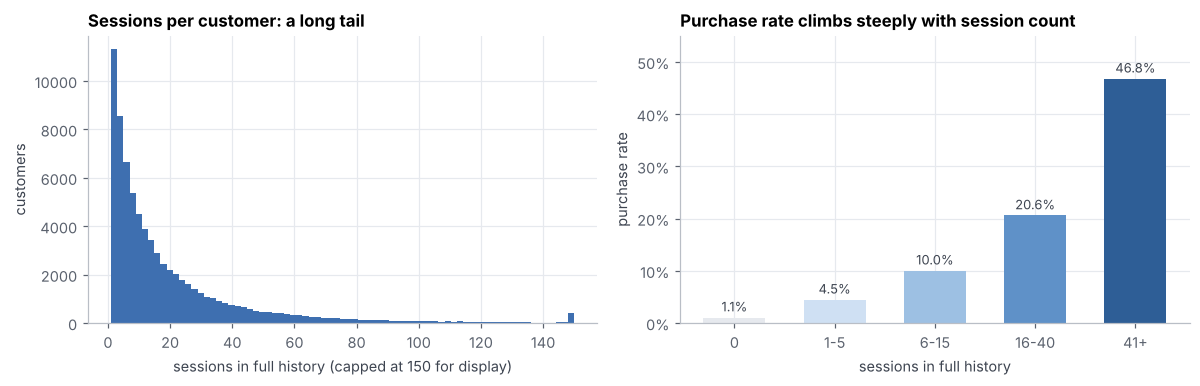

,purchase_rate,customers
n_sessions,,
0,1.1%,"5,173"
1-5,4.5%,"18,780"
6-15,10.0%,"17,366"
16-40,20.6%,"14,989"
41+,46.8%,"7,692"


In [23]:
per = se.groupby('customer_id').size().rename('n_sessions')
d = train.merge(per, on='customer_id', how='left').fillna({'n_sessions': 0})

print(f'train customers with zero sessions: {(d.n_sessions == 0).sum():,} ({(d.n_sessions == 0).mean():.1%})')
print(f'sessions per customer (those with any): median {per.median():.0f}, mean {per.mean():.1f}, max {per.max():,}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(per.clip(upper=150), bins=75, color=INK)
axes[0].set_title('Sessions per customer: a long tail')
axes[0].set_xlabel('sessions in full history (capped at 150 for display)'); axes[0].set_ylabel('customers')

bands = pd.cut(d.n_sessions, [-1, 0, 5, 15, 40, 10_000], labels=['0', '1-5', '6-15', '16-40', '41+'])
g = d.groupby(bands, observed=True).target.agg(['mean', 'size'])
bars = axes[1].bar(g.index.astype(str), g['mean'], color=['#e6e9ee'] + RAMP, width=0.62)
label_bars(axes[1], bars)
axes[1].set_title('Purchase rate climbs steeply with session count')
axes[1].set_xlabel('sessions in full history'); axes[1].set_ylabel('purchase rate')
axes[1].set_ylim(0, 0.55); pct(axes[1])
plt.tight_layout(); plt.show()
g.rename(columns={'mean': 'purchase_rate', 'size': 'customers'}).style.format({'purchase_rate': '{:.1%}', 'customers': '{:,}'})

**Found.** Customers with no sessions almost never buy; customers with 41+ buy nearly half the time. Session count on its own spans a range most features never reach.

**This is the master variable.** Hold onto it — the next section shows that most other things in my tables that *look* predictive are really just session count in disguise.

### 5.2 Recency — when did they last visit?

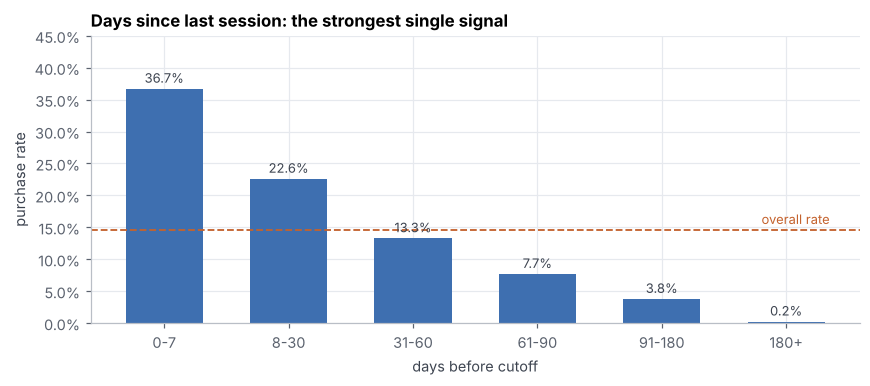

In [24]:
last = se.groupby('customer_id').session_date.max()
d['days_since_session'] = d.customer_id.map((CUTOFF - last).dt.days)

edges = [-1, 7, 30, 60, 90, 180, 10_000]
labels = ['0-7', '8-30', '31-60', '61-90', '91-180', '180+']
g = d.groupby(pd.cut(d.days_since_session, edges, labels=labels), observed=True).target.mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(g.index.astype(str), g.values, color=INK, width=0.62)
label_bars(ax, bars)
ax.axhline(train.target.mean(), color=FLAG, lw=1.2, ls='--')
ax.annotate('overall rate', (5.35, train.target.mean()), xytext=(0, 4), textcoords='offset points',
            ha='right', color=FLAG, fontsize=8.5)
ax.set_title('Days since last session: the strongest single signal')
ax.set_xlabel('days before cutoff'); ax.set_ylabel('purchase rate')
ax.set_ylim(0, 0.45); pct(ax)
plt.tight_layout(); plt.show()

**Found.** From ~37% for a visit in the last week down to under 1% beyond six months. Recency and frequency together will carry most of any model — which is why the LightGBM baseline will be strong.

### 5.3 Three signals that turn out to be session count in disguise

Each of these looks strongly predictive on its own. For each, I compare the raw view with the same comparison **inside session-count bands** — customers with similar activity levels. If the gap survives, it's real signal. If it disappears, it was activity all along.

**Why this is the most important analysis in my section:** a model will happily use these features, and SHAP will happily report them as drivers. If a CRM user then reads "campaign exposure raises purchase probability" off a dashboard, the business makes a wrong decision. Knowing which correlations are hollow is how you avoid building that dashboard.

In [25]:
band = pd.cut(d.n_sessions, [0, 5, 15, 40, 10_000], labels=['1-5', '6-15', '16-40', '41+'])
active = d.n_sessions > 0

def raw_vs_controlled(flag, yes_label, no_label, title):
    dd = d[active].assign(flag=flag[active], band=band[active])
    raw = dd.groupby('flag').target.mean()
    ctl = dd.pivot_table(index='band', columns='flag', values='target', aggfunc='mean', observed=True)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={'width_ratios': [1, 2.2]})
    b = axes[0].bar([no_label, yes_label], [raw.get(False), raw.get(True)], color=[GREY, INK], width=0.55)
    label_bars(axes[0], b)
    axes[0].set_title('Raw'); axes[0].set_ylabel('purchase rate'); axes[0].set_ylim(0, 0.55); pct(axes[0])

    x = np.arange(len(ctl)); w = 0.36
    b1 = axes[1].bar(x - w / 2, ctl[False], w - 0.03, color=GREY, label=no_label)
    b2 = axes[1].bar(x + w / 2, ctl[True],  w - 0.03, color=INK,  label=yes_label)
    label_bars(axes[1], b1, size=7.5); label_bars(axes[1], b2, size=7.5)
    axes[1].set_xticks(x, [f'{i} sessions' for i in ctl.index])
    axes[1].set_title('Same comparison within session-count bands')
    axes[1].set_ylim(0, 0.55); pct(axes[1]); axes[1].legend(loc='upper left')
    fig.suptitle(title, x=0.01, ha='left', fontsize=11.5, fontweight='bold')
    plt.tight_layout(); plt.show()
    return raw, ctl

#### (a) Has the customer ever come in through a campaign?

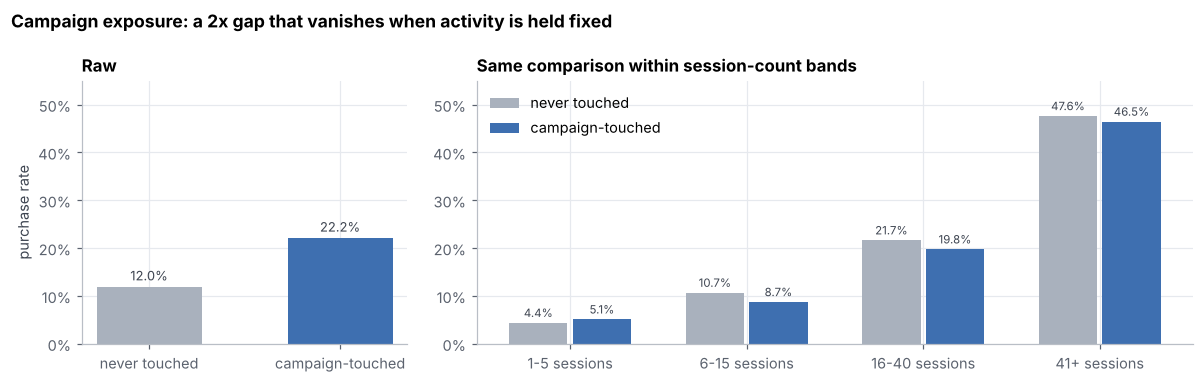

median sessions | touched: 22.0 | never touched: 7.0


In [26]:
touched = d.customer_id.isin(set(se.loc[se.from_campaign, 'customer_id']))
raw, ctl = raw_vs_controlled(touched, 'campaign-touched', 'never touched',
                             'Campaign exposure: a 2x gap that vanishes when activity is held fixed')
print('median sessions | touched:', d.loc[touched & active, 'n_sessions'].median(),
      '| never touched:', d.loc[~touched & active, 'n_sessions'].median())

**Found — the headline finding of my section.** Raw, campaign-touched customers buy at roughly twice the rate. Within each activity band, the gap disappears — in the middle bands it even reverses slightly.

The reason is in the medians: touched customers have far more sessions. More sessions means more chances to land on a campaign *and* more likelihood of buying anyway. The campaign is riding along with activity, not driving it.

**Connection to the business.** This is the customer-level version of what same-day attribution does at the campaign level (4.3). The Head of Marketing's complaint — *"I need to see which campaigns pay back"* — can't be answered from attributed revenue, because attribution credits campaigns for active customers who'd have bought regardless. It's the same structural problem as the tier-restricted offers in the retention data, and it's further evidence for declining **W10**: honest measurement needs a control group.

**Connection to the model.** Don't include "ever touched by a campaign" as a feature without also including session count — or SHAP will report it as a driver it isn't.

#### (b) Device

median sessions by main device: {'desktop': 5.0, 'mobile': 14.0, 'tablet': 1.0}
customers by main device: {'mobile': 43722, 'desktop': 14484, 'tablet': 621}


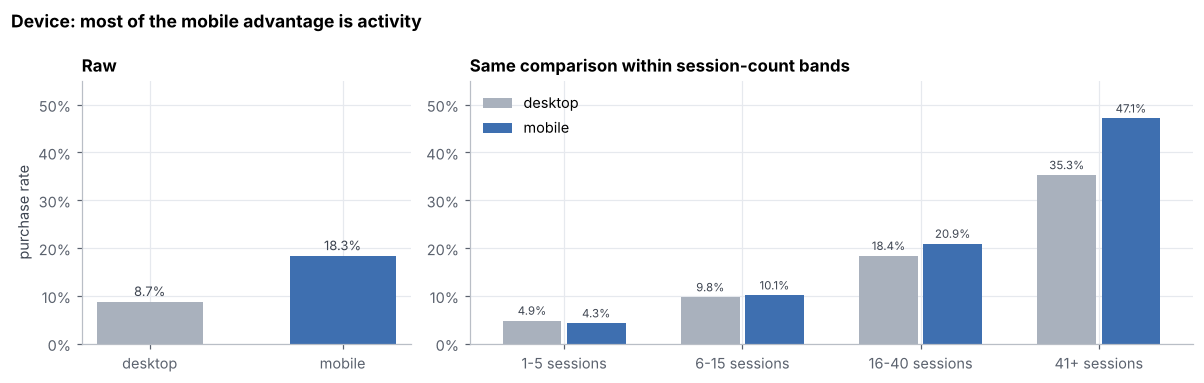

In [27]:
dev = se.groupby('customer_id').device_type.agg(lambda s: s.mode().iat[0])
d['main_device'] = d.customer_id.map(dev)
print('median sessions by main device:', d[active].groupby('main_device').n_sessions.median().to_dict())
print('customers by main device:', d[active].main_device.value_counts().to_dict())

mob = d.main_device.eq('mobile')
sub = active & d.main_device.isin(['mobile', 'desktop'])
d_saved = d
d = d[sub]                        # compare mobile vs desktop only; tablet n is tiny
raw, ctl = raw_vs_controlled(mob[sub], 'mobile', 'desktop',
                             'Device: most of the mobile advantage is activity')
d = d_saved

**Found — partly hollow.** Mobile-first customers look about twice as likely to buy, but their median session count is nearly three times desktop's. Within bands the gap mostly closes: among light users mobile and desktop are level, and a residual mobile advantage appears only in the two most active bands.

So device carries *some* signal, much less than it appears. Tablet is excluded from the comparison — too few customers to say anything (and their median of one session explains their very low raw rate).

#### (c) Visiting from outside your home region

sessions from a region other than the customer's home: 7.9%


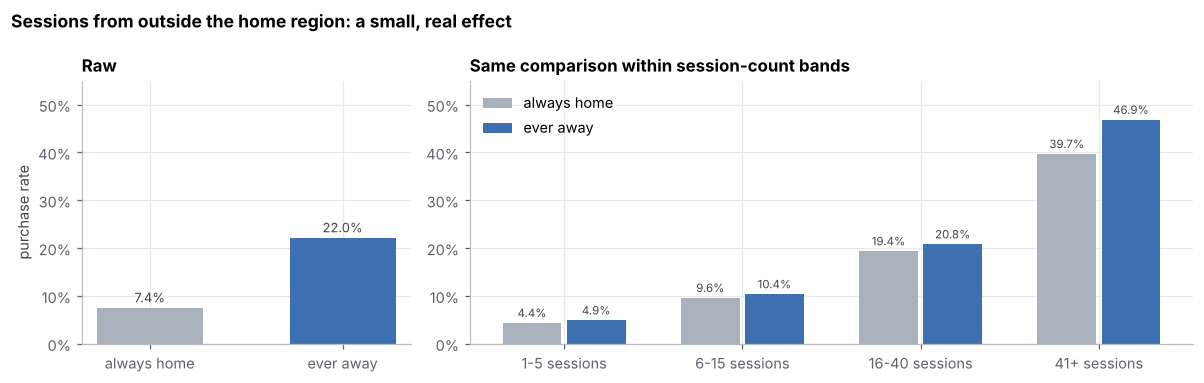

In [28]:
m = se[['customer_id', 'geo_ip_region']].merge(customers, on='customer_id')
away_share = (m.geo_ip_region != m.region).groupby(m.customer_id).mean()
print(f'sessions from a region other than the customer\'s home: {(m.geo_ip_region != m.region).mean():.1%}')
any_away = d.customer_id.map(away_share).fillna(0) > 0
raw, ctl = raw_vs_controlled(any_away, 'ever away', 'always home',
                             'Sessions from outside the home region: a small, real effect')

**Found — the one that survives.** About 8% of sessions come from a region other than the customer's home (`DATA_README` says this happens; it's travel, VPNs, or work). Raw it looks strong; controlled, it shrinks to a few points — but it stays positive in every band.

A plausible reading: someone who browses from several places is more engaged with the brand. Worth keeping as a feature, with a modest expectation.

### 5.4 What survives: the *shape* of activity

This is the evidence that matters most for the deep-learning case. If session count explains almost everything, does the **order** of sessions add anything? Compare customers with **the same number of sessions** in the last 90 days, split by whether their visits were rising, flat or falling across that window.

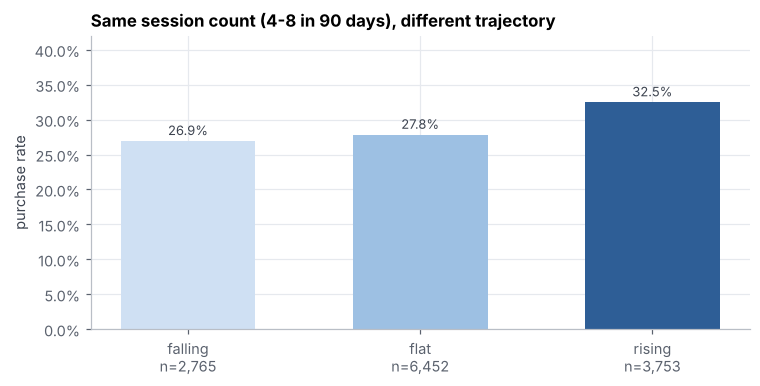

In [29]:
w = se[se.session_date > CUTOFF - pd.Timedelta(days=90)].copy()
age = (CUTOFF - w.session_date).dt.days
w['third'] = np.select([age < 30, age < 60], ['last 30d', 'middle 30d'], 'first 30d')
p = w.pivot_table(index='customer_id', columns='third', values='session_id', aggfunc='count', fill_value=0)
p['total'] = p.sum(axis=1)
p['shape'] = np.select([p['last 30d'] - p['first 30d'] > 1, p['last 30d'] - p['first 30d'] < -1],
                       ['rising', 'falling'], 'flat')

jt = train.merge(p, on='customer_id')
matched = jt[jt.total.between(4, 8)]
g = matched.groupby('shape').target.agg(['mean', 'size']).reindex(['falling', 'flat', 'rising'])

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar([f'{s}\nn={n:,}' for s, n in zip(g.index, g['size'])], g['mean'],
              color=[RAMP[0], RAMP[1], RAMP[3]], width=0.58)
label_bars(ax, bars)
ax.set_title('Same session count (4-8 in 90 days), different trajectory')
ax.set_ylabel('purchase rate'); ax.set_ylim(0, 0.42); pct(ax)
plt.tight_layout(); plt.show()

**Found.** Holding the total fixed at 4–8 sessions, customers whose visits were **rising** buy at a noticeably higher rate than those whose visits were **falling**. Same count, different shape, different outcome.

**This is the case for the sequence model in one chart.** A count-based feature can't see this; LightGBM only sees it if someone hand-engineers a trend feature — and then only the trend they thought to build. A GRU reading the sessions in order sees the trajectory directly.

The honest caveat: the gap is a few points, not a revolution. It's evidence the sequence carries *some* signal beyond count — not proof a GRU will beat the baseline. Which is the right expectation to set at PR1.

### 5.5 The link to `transactions`: sessions are where orders happen

orders with NO session that day: 0 of 301,243


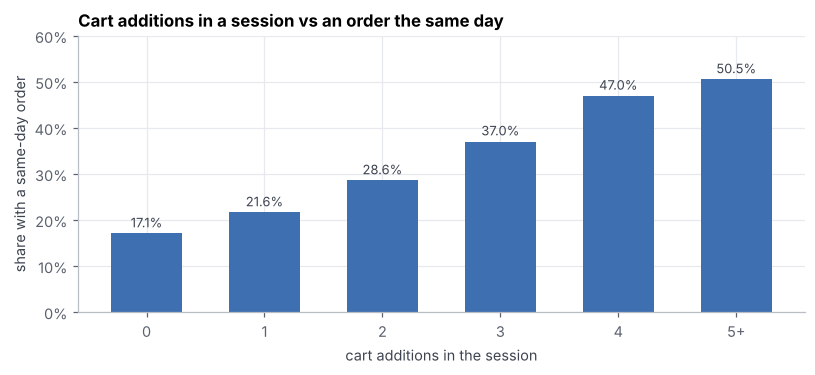

In [30]:
sd_ = se[['customer_id', 'session_date', 'cart_additions']].rename(columns={'session_date': 'date'})
tx['date'] = pd.to_datetime(tx.transaction_timestamp)
od = tx.groupby(['customer_id', 'date']).size().rename('orders').reset_index()

k = sd_.merge(od, on=['customer_id', 'date'], how='left')
k['ordered_same_day'] = k.orders.notna()

orphans = ~od.set_index(['customer_id', 'date']).index.isin(sd_.set_index(['customer_id', 'date']).index)
print(f'orders with NO session that day: {orphans.sum():,} of {len(od):,}')

g = k.groupby(k.cart_additions.clip(upper=5)).ordered_same_day.mean()
fig, ax = plt.subplots(figsize=(7.5, 3.5))
bars = ax.bar([str(i) if i < 5 else '5+' for i in g.index], g.values, color=INK, width=0.6)
label_bars(ax, bars)
ax.set_title('Cart additions in a session vs an order the same day')
ax.set_xlabel('cart additions in the session'); ax.set_ylabel('share with a same-day order')
ax.set_ylim(0, 0.6); pct(ax)
plt.tight_layout(); plt.show()

**Found two structural facts.**

1. **Every order happens on a day the customer also had a session.** Not most — every one. So in this dataset, ordering is a subset of browsing. That's a property of how the data was generated, and it means a customer with no sessions in a window cannot have ordered in it.
2. **Cart additions rise smoothly toward an order**, as you'd expect from a purchase funnel.

**Connection to the sequence model.** Point 1 is a design decision: sessions and orders can be merged into **one event stream**, with orders as a type of event that always lands on a session day. That's simpler than two parallel sequences, and the cart-additions gradient suggests each session should carry its `cart_additions` as an input.

### 5.6 `geo_data` against the target

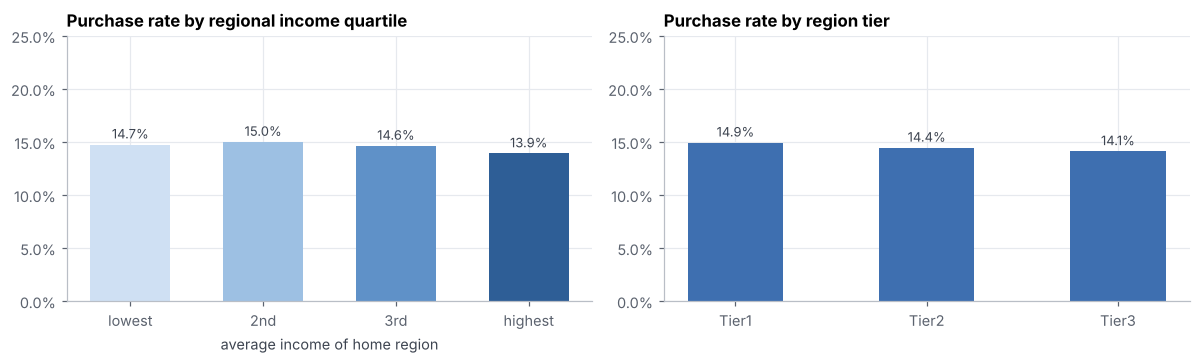

,correlation with target
average_income,-0.0087
urban_ratio,-0.0041
internet_penetration,-0.0004


In [31]:
jg = (train.merge(customers, on='customer_id')
           .merge(geo, left_on='region', right_on='geo_ip_region'))
cols = ['average_income', 'urban_ratio', 'internet_penetration']
corrs = jg[cols + ['target']].corr()['target'].drop('target')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
q = jg.groupby(pd.qcut(jg.average_income, 4, labels=['lowest', '2nd', '3rd', 'highest']),
               observed=True).target.mean()
bars = axes[0].bar(q.index.astype(str), q.values, color=RAMP, width=0.6)
label_bars(axes[0], bars)
axes[0].set_title('Purchase rate by regional income quartile')
axes[0].set_ylim(0, 0.25); pct(axes[0]); axes[0].set_xlabel('average income of home region')

t = jg.groupby('region_tier').target.mean()
bars = axes[1].bar(t.index, t.values, color=INK, width=0.5)
label_bars(axes[1], bars)
axes[1].set_title('Purchase rate by region tier'); axes[1].set_ylim(0, 0.25); pct(axes[1])
plt.tight_layout(); plt.show()
corrs.to_frame('correlation with target').style.format('{:+.4f}')

**Found — no signal at all.** Purchase rate is flat across income quartiles and region tiers, and every correlation is effectively zero.

**Two connections from that:**

- **For the model:** geo features are unlikely to help. Include them in the first run so the importance plot can show it, but don't spend engineering time on them.
- **For the Responsible AI section — this is good news.** A common fairness worry is that a retention model learns to deprioritise poorer regions. On this data, regional income carries no predictive weight, so that particular harm has little to latch onto. *But* tier does carry huge weight (the shared EDA found roughly a tenfold spread), and tier is built from spend — so the fairness risk lives there, not in geography. That's a sharper statement than a generic "we checked for bias".

---

## 6. What this means for the sequence model

The sequence model is the reason my tables matter most. Three practical questions it raises.

In [32]:
last180 = se[se.session_date > CUTOFF - pd.Timedelta(days=180)].groupby('customer_id').size()
full = per
rows = []
for L in [20, 50, 100]:
    rows.append({'max sequence length': L,
                 'customers fully covered (full history)': (full <= L).mean(),
                 'customers fully covered (last 180 days)': (last180 <= L).mean()})
pd.DataFrame(rows).set_index('max sequence length').style.format('{:.1%}')

,customers fully covered (full history),customers fully covered (last 180 days)
max sequence length,,
20,69.7%,94.2%
50,90.9%,99.7%
100,98.1%,100.0%


**1. How long should sequences be?** Truncating to the most recent 50 events covers the *entire* history of about 91% of customers, and the last six months of 99.7%. Padding to the maximum (528) would spend almost all compute on padding.

**2. What goes in each event?** From this notebook, each session can carry: days before cutoff, `session_duration` (log-transformed), `pages_viewed` with its missing flag, `cart_additions`, `bounce_flag`, `device_type`, `traffic_source`, `from_campaign`, and whether it was away from home. Orders slot into the same stream (5.5).

**3. How to encode time?** As **days before cutoff**, not as calendar dates. The business grew strongly year on year; absolute dates let the model learn "2024 is busier" instead of "this customer is slowing down" — which is the thing 5.4 shows actually matters.

And the customers with **no sessions at all** get an empty sequence. That's around 8% of training data. The tabular branch of the model has to carry them, and that path needs testing explicitly — it's an easy thing to break and an easy thing to be asked about.

---

## 7. Save

In [33]:
keep = ['session_id', 'customer_id', 'session_date', 'session_duration', 'pages_viewed',
        'cart_additions', 'bounce_flag', 'traffic_source', 'device_type', 'campaign_id',
        'geo_ip_region', 'from_campaign', 'pages_viewed_missing', 'duration_corrupt']
sessions_out = se[keep]
sessions_out.to_csv(OUT_DIR / 'sessions.csv', index=False)
geo.to_csv(OUT_DIR / 'geo_data.csv', index=False)
cdp.to_csv(OUT_DIR / 'campaign_daily_performance.csv', index=False)

qa = pd.DataFrame(QUALITY); qa.index = range(1, len(qa) + 1)
qa.to_csv(OUT_DIR / 'quality_log.csv', index_label='#')

readme = f"""# Browsing dataset (Person A)

Cleaned output of `personA_browsing.ipynb`. Source: ShopSphere data pack, snapshot {CUTOFF:%d %b %Y}.
Cleaning only fixes representation. Nothing here is fitted: imputation, scaling and
transforms happen in the model pipeline, on training rows only.

## Files

| File | Rows | Grain |
|---|---|---|
| sessions.csv | {len(sessions_out):,} | one website/app session |
| geo_data.csv | {len(geo):,} | one region |
| campaign_daily_performance.csv | {len(cdp):,} | one campaign-day |
| quality_log.csv | {len(qa)} | one data-quality issue found and how it was handled |

## sessions.csv columns

| Column | Type | Notes |
|---|---|---|
| session_id | int | unique |
| customer_id | int | joins customers, train, test |
| session_date | date | renamed from session_timestamp (date only, no time). All <= cutoff |
| session_duration | float, seconds | **null for {int(sessions_out.duration_corrupt.sum()):,} corrupted sessions** (see duration_corrupt) |
| pages_viewed | float | {int(sessions_out.pages_viewed.isna().sum()):,} still null (impute in pipeline). Bounced nulls set to 1 |
| cart_additions | int | unchanged. {int(more.sum())} sessions add more items than pages viewed: kept (one page can add several items, see 2.5) |
| bounce_flag | bool | six source encodings mapped. Rate ~0.5%, implausibly low: treat as weak |
| traffic_source | str | lowercase: ads, direct, email, organic, social |
| device_type | str | lowercase: desktop, mobile, tablet |
| campaign_id | nullable int | blank = not from a campaign (documented meaning, not missing) |
| geo_ip_region | str | joins geo_data. May differ from the customer's home region |
| from_campaign | bool | campaign_id is not blank |
| pages_viewed_missing | bool | pages_viewed was null in the source |
| duration_corrupt | bool | source duration > 5h: corrupted cluster, value nulled |

## geo_data.csv and campaign_daily_performance.csv

Validated, unchanged apart from `date` parsed to a date. Both passed every integrity check.
campaign_daily_performance reconciles exactly with sessions.csv (100,401 campaign sessions on
both sides), so it's a pre-aggregated view of the same data, useful for the W6 dashboard.
`spend` is actual; marketing_campaigns.campaign_budget is the plan (94 campaigns overspent, max 5.8%).

## Not done here, on purpose

- Imputing pages_viewed / session_duration: fit on the training split only.
- Feature engineering and the 30 Sep 2024 cutoff for features: features.py.
"""
(OUT_DIR / 'README.md').write_text(readme)

print('written to', OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print(f'  {f.name:<34} {f.stat().st_size/1e6:7.1f} MB')
qa

written to /home/claude/work/browsing_run/browsing_dataset
  README.md                              0.0 MB
  campaign_daily_performance.csv         0.5 MB
  geo_data.csv                           0.0 MB
  quality_log.csv                        0.0 MB
  sessions.csv                         122.6 MB


,table,issue,rows,action
1,sessions,bounce_flag in 6 encodings,1442550,mapped to bool
2,sessions,traffic_source case variants,10,"15 spellings -> 5: ['ads', 'direct', 'email', ..."
3,sessions,device_type case variants,6,"9 spellings -> 3: ['desktop', 'mobile', 'tablet']"
4,sessions,pages_viewed null on bounced sessions,349,set to 1 (a bounce is 1 page by definition)
5,sessions,pages_viewed null otherwise,71609,flagged; imputation deferred to pipeline
6,sessions,cart_additions > pages_viewed,144,"kept: tail of the count, several items can be ..."
7,sessions,session_duration in corrupted cluster (>5h),1484,"nulled, flagged: normal activity over hours, u..."
8,sessions,session_duration 1h-5h (natural tail),560,kept; transform in pipeline
9,sessions,campaign_id blank,1342149,"documented meaning: not from a campaign. Flag,..."
10,campaign_daily,total spend exceeds marketing_campaigns.campai...,94,"kept; budget is a plan, spend is actual"


---

## 8. Summary

*Revised 19 Nov 2026: the decision in 2.5 changed from capping cart additions to keeping them.*

### Cleaning decisions I'll be asked to defend

| Decision | Reasoning |
|---|---|
| Map six `bounce_flag` spellings, **fail loudly** on anything else | A silent default would turn an unseen token into `False` without anyone noticing |
| Lowercase `traffic_source` and `device_type` | Safe *only* because every variant differs by case alone — checked before applying |
| Set `pages_viewed = 1` for bounced sessions with a null | Deduction, not imputation: every bounced session with a value has exactly 1 |
| Leave other `pages_viewed` nulls for the pipeline | Not structural; a fitted imputation must be learned from training rows only |
| Keep `cart_additions` above `pages_viewed` (144 rows) | Not a fault: one page can add several items. The 144 are the smooth tail of the count (one extra item in 134), rarer as visits get longer, with no cluster or gap. First version capped them; revised 19 Nov after testing the pattern |
| Null durations over 5 hours (1,484 rows); keep the rest | Not "too long" but *corrupted*: same activity as a normal visit spread over hours, uncorrelated with pages, separated from real sessions by an empty gap. A fixed threshold inside the gap isn't tuned to the data, unlike a percentile |
| Keep blank `campaign_id` as blank, add `from_campaign` | Documented meaning; filling would invent campaign traffic |
| Flag `bounce_flag` as implausibly low | 0.5% is not a credible e-commerce bounce rate |

### The connections

1. **`campaign_daily_performance` is `sessions.csv` aggregated.** They reconcile row for row. For the model, the daily table is redundant; for the W6 dashboard, it's the ready-made source.
2. **Session count is the master variable.** Campaign exposure, device and region all *look* predictive; most of each collapses once activity is held fixed.
3. **Campaign exposure has no effect beyond activity.** The customer-level echo of same-day attribution's flaw — and more evidence for declining W10.
4. **Trajectory survives where count doesn't.** At matched volume, rising activity beats falling. That's the empirical case for a sequence model — modest, and honest about it.
5. **Every order lands on a session day.** Sessions and orders can share one event stream.
6. **Geography carries no signal.** Useless as features; reassuring for fairness — the fairness risk sits in tier, not region.

### Questions I should expect at PR1

- *A 25-hour session isn't impossible — why delete it?* — Because the evidence says corrupted, not long: normal page counts over hours, no correlation with activity, and a gap separating the cluster from real sessions. It's 1,484 rows, not just the 79 over 24h.
- *More cart adds than pages: isn't that impossible?* — Not when one page can add several items. The 144 sessions are mostly one extra item on 1–3 page visits, and the rate falls smoothly as pages rise: a tail, not a fault. I first capped them and reversed that after checking the pattern.
- *Why not cap at a percentile?* — A percentile moves with the data, so it's learned and belongs after the split. The 5h rule sits in an empty gap, so it removes the same rows on any split.
- *Why not fill `email`-style nulls with zero?* (if asked about `pages_viewed`) — Zero is a real value; it'd make "unknown" indistinguishable from "viewed nothing".
- *Is campaign exposure a useful feature?* — Only alongside session count; on its own it's a proxy, and SHAP would mis-report it.
- *Why a sequence model if count explains so much?* — Because 5.4 shows shape adds signal count can't see. The gap is modest; we'll report whichever model wins.
- *What happens to customers with no sessions?* — Empty sequence; the tabular branch carries them; that path is tested separately.

### Cleaning summary chart (slide chart 1)

Every count below is computed from this notebook's variables, so the chart can't drift from the cleaning above.

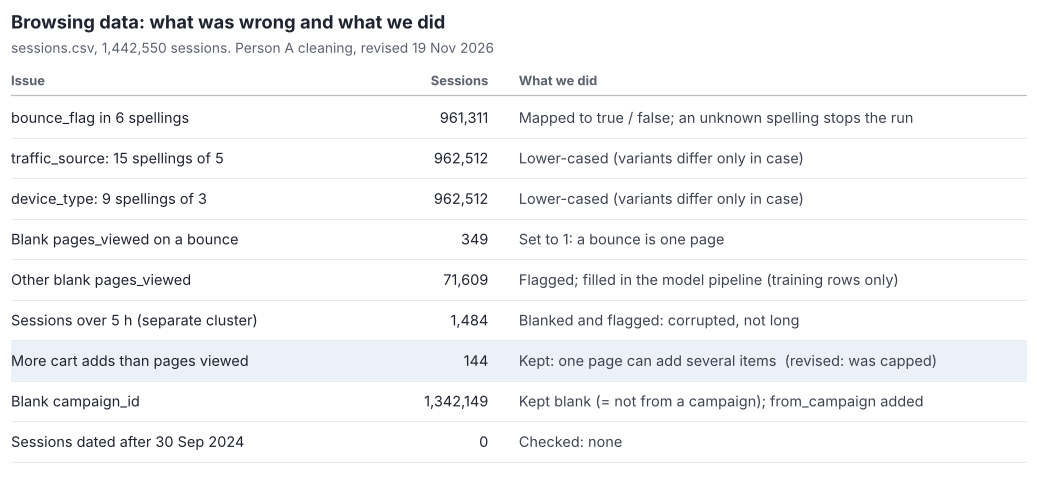

In [34]:
rows = [
    ('bounce_flag in 6 spellings', (~se_raw.bounce_flag.astype(str).isin(['0', '1'])).sum(),
     'Mapped to true / false; an unknown spelling stops the run'),
    ('traffic_source: 15 spellings of 5', (se_raw.traffic_source.astype(str) != se.traffic_source).sum(),
     'Lower-cased (variants differ only in case)'),
    ('device_type: 9 spellings of 3', (se_raw.device_type.astype(str) != se.device_type).sum(),
     'Lower-cased (variants differ only in case)'),
    ('Blank pages_viewed on a bounce', deducible.sum(), 'Set to 1: a bounce is one page'),
    ('Other blank pages_viewed', se.pages_viewed.isna().sum(), 'Flagged; filled in the model pipeline (training rows only)'),
    ('Sessions over 5 h (separate cluster)', corrupt.sum(), 'Blanked and flagged: corrupted, not long'),
    ('More cart adds than pages viewed', more.sum(), 'Kept: one page can add several items'),
    ('Blank campaign_id', (~se.from_campaign).sum(), 'Kept blank (= not from a campaign); from_campaign added'),
    ('Sessions dated after 30 Sep 2024', after, 'Checked: none'),
]
REVISED = 'More cart adds than pages viewed'

fig, ax = plt.subplots(figsize=(9.6, 4.5), dpi=110)
ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(len(rows) + 1.4, -0.9)
x_issue, x_n, x_fix = 0.0, 0.47, 0.50
ax.text(0, -0.55, 'Browsing data: what was wrong and what we did', fontsize=12, fontweight='bold', color='#1f2430')
ax.text(0, 0.05, f'sessions.csv, {len(se):,} sessions. Person A cleaning, revised 19 Nov 2026', fontsize=9, color='#5b626e')
for x, label, ha in [(x_issue, 'Issue', 'left'), (x_n, 'Sessions', 'right'), (x_fix, 'What we did', 'left')]:
    ax.text(x, 0.85, label, fontsize=8.5, fontweight='bold', color='#5b626e', ha=ha)
ax.plot([0, 1], [1.1, 1.1], color='#b9bec6', lw=0.8)
for k, (issue, n, fix) in enumerate(rows):
    y = k + 1.65
    if issue == REVISED:
        ax.add_patch(plt.Rectangle((-0.01, y - 0.48), 1.02, 0.96, color='#eaf1f9', zorder=0))
        fix += '  (revised: was capped)'
    ax.text(x_issue, y, issue, fontsize=9.5, color='#1f2430', va='center')
    ax.text(x_n, y, f'{int(n):,}', fontsize=9.5, color='#1f2430', va='center', ha='right')
    ax.text(x_fix, y, fix, fontsize=9.5, color='#3d4450', va='center')
    ax.plot([0, 1], [y + 0.5, y + 0.5], color='#e6e9ee', lw=0.6)
plt.tight_layout()
fig.savefig(OUT_DIR / 'chart1_cleaning_issues.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()